In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from copy import deepcopy

# Sklearn imports
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegressionCV
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_squared_error, brier_score_loss
from sklearn.calibration import calibration_curve
from sklearn.model_selection import train_test_split
from sklearn.base import clone

# TableOne for descriptive statistics
from tableone import TableOne


# Data loading and initial Analysis

In [2]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Step 1: Load and standardize column names
files = [
    ("survey_results_public2023.csv", 2023),
    ("Stack Overflow Annual Developer Survey2024.csv", 2024),
    ("results2022.csv", 2022),
]
dfs = []
for file, year in files:
    df = pd.read_csv(file)
    df.columns = df.columns.str.strip().str.replace(' ', '').str.replace('_', '').str.lower()
    df['year'] = year
    dfs.append(df)


# Standardize all column names (lowercase, remove spaces/underscores)
for i, df in enumerate(dfs):
    dfs[i].columns = dfs[i].columns.str.strip().str.replace(' ', '').str.replace('_', '').str.lower()
# Step 2: Concatenate all dataframes
df_all = pd.concat(dfs, ignore_index=True, join='outer')

# Step 3: Detect country column dynamically
country_col = [col for col in df_all.columns if 'country' in col][0]

# Step 4: Filter for U.S. respondents only
df_us = df_all[df_all[country_col] == 'United States of America'].copy()

# Step 5: Define relevant columns (must be lowercase!)
requested_cols = [
    'remotework','workexp', 'convertedcompyearly', 'age', 'employment', 'edlevel',
    'yearscode','yearscodepro', 'devtype', 'orgsize', 'industry', country_col,'year'
]





In [3]:
print(df_us.shape)

(43285, 138)


In [4]:
# Only use columns that actually exist
feature_cols = [col for col in requested_cols if col in df_us.columns]

# Subset data
df_us = df_us[feature_cols].copy()
df_us.head()
print(df_us.shape)

(43285, 13)


In [5]:
#statistics of df_us
df_us.describe(include='all')

,remotework,workexp,convertedcompyearly,age,employment,edlevel,yearscode,yearscodepro,devtype,orgsize,industry,country,year
count,37193,22535.000000,2.526500e+04,43057,43267,43257,43077,35196,39612,33951,13616,43285,43285.000000
unique,5,NaN,NaN,8,116,10,52,52,3023,10,23,1,NaN
top,Remote,NaN,NaN,25-34 years old,"Employed, full-time","Bachelor’s degree (B.A., B.S., B.Eng., etc.)",10,10,"Developer, full-stack","10,000 or more employees","Information Services, IT, Software Development...",United States of America,NaN
freq,13655,NaN,NaN,14279,30149,21780,3147,2309,10795,6930,3185,43285,NaN
mean,NaN,14.181806,2.427895e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2022.943445
std,NaN,10.447148,7.849089e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.752342
min,NaN,0.000000,1.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2022.000000
25%,NaN,6.000000,1.060000e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2022.000000
50%,NaN,11.000000,1.480000e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2023.000000
75%,NaN,20.000000,2.000000e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024.000000


we notice that the Industry is missing in the data and because its important confounder we use method to complete missing data

In [6]:

def convert_experience_to_numeric(x):
    if pd.isna(x):
        return np.nan
    if isinstance(x, str):
        x = x.strip()
        if x.lower() == 'less than 1 year':
            return 0.5
        elif x.lower() == 'more than 50 years':
            return 51
        else:
            try:
                return float(x)
            except ValueError:
                return np.nan
    return x  # If already numeric





### data complition using RandomForestClassifier

In [7]:
df_to_complete=df_us.copy()

In [9]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# -----------------------------------------------------------------------------
# Inputs you already have in your session:
# - df_us: your original dataframe
# - feature_cols: list of feature column names to use for prediction
# -----------------------------------------------------------------------------

df_to_complete = df_us.copy()

# Step 1: split rows by availability of target
df_train = df_to_complete[df_to_complete['industry'].notna()].copy()
df_missing = df_to_complete[df_to_complete['industry'].isna()].copy()

# Step 2: encode target
le_industry = LabelEncoder()
df_train['industry_enc'] = le_industry.fit_transform(df_train['industry'])

# Step 3: encode features with label encoders per column
encoded_features = pd.DataFrame(index=df_train.index)
encoders = {}

for col in feature_cols:
    le = LabelEncoder()
    filled = df_train[col].astype(str).fillna("NA")
    le.fit(filled)
    encoded_features[col] = le.transform(filled)
    encoders[col] = le

# Step 4: split train and validation
X = encoded_features
y = df_train['industry_enc']

X_train_split, X_val, y_train_split, y_val = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Step 5: train model
model = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1)
model.fit(X_train_split, y_train_split)

# Step 6: evaluate
y_pred = model.predict(X_val)

print(" Accuracy:", accuracy_score(y_val, y_pred))

# Build consistent labels and names for the report
labels_present = np.unique(y_val)                         # integer class ids present in validation
target_names = le_industry.classes_[labels_present]       # matching names in the same order

print("\n Classification Report:")
print(classification_report(
    y_val, y_pred,
    labels=labels_present,
    target_names=target_names
))

print("\n Confusion Matrix:")
print(confusion_matrix(y_val, y_pred, labels=labels_present))

# Step 7: predict missing industries if any
def safe_transform_with_unseen_to_NA(series, fitted_le: LabelEncoder):
    """Map unseen categories to 'NA' before transforming."""
    s = series.astype(str).fillna("NA")
    # Ensure 'NA' is in classes. If not, extend classes to include it.
    if "NA" not in fitted_le.classes_:
        fitted_le.classes_ = np.append(fitted_le.classes_, "NA")
    # Replace unseen values with 'NA'
    mask_unseen = ~np.isin(s.values, fitted_le.classes_)
    if mask_unseen.any():
        s = s.where(~mask_unseen, "NA")
    return fitted_le.transform(s)

if not df_missing.empty:
    encoded_missing = pd.DataFrame(index=df_missing.index)
    for col in feature_cols:
        encoded_missing[col] = safe_transform_with_unseen_to_NA(df_missing[col], encoders[col])

    preds_missing = model.predict(encoded_missing)
    pred_labels = le_industry.inverse_transform(preds_missing)

    # Fill predictions back
    df_missing = df_missing.copy()
    df_missing['industry'] = pred_labels

    # Combine back and keep original row order
    df_completed = pd.concat(
        [df_train.drop(columns=['industry_enc']), df_missing],
        axis=0
    ).sort_index()
else:
    print("No missing values in 'industry'. Skipping imputation.")
    df_completed = df_train.drop(columns=['industry_enc'])

# Step 8: save
df_completed.to_csv("df_complete.csv", index=False)
print(" Saved completed dataset to df_complete.csv")


 Accuracy: 0.9711138310893512

 Classification Report:
                                                                     precision    recall  f1-score   support

                                               Advertising Services       1.00      0.80      0.89        65
                                         Banking/Financial Services       0.94      0.96      0.95        70
                               Computer Systems Design and Services       0.91      0.80      0.85        49
                                                             Energy       0.79      0.41      0.54        37
                                                 Financial Services       0.96      1.00      0.98       295
                                                            Fintech       0.83      0.93      0.88        83
                                                         Government       0.89      0.98      0.93       108
                                                         Healthcare     

c:\Users\Yuval Margolin\PycharmProjects\pythonProject\venv\lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Yuval Margolin\PycharmProjects\pythonProject\venv\lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Yuval Margolin\PycharmProjects\pythonProject\venv\lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf

 Saved completed dataset to df_complete.csv


In [10]:
#load df_completed
df_completed = pd.read_csv("df_complete.csv")

In [11]:
df_completed.describe(include='all')

,remotework,workexp,convertedcompyearly,age,employment,edlevel,yearscode,yearscodepro,devtype,orgsize,industry,country,year
count,37193,22535.000000,2.526500e+04,43057,43267,43257,43077,35196,39612,33951,43285,43285,43285.000000
unique,5,NaN,NaN,8,116,10,52,52,3023,10,23,1,NaN
top,Remote,NaN,NaN,25-34 years old,"Employed, full-time","Bachelor’s degree (B.A., B.S., B.Eng., etc.)",10,10,"Developer, full-stack","10,000 or more employees","Transportation, or Supply Chain",United States of America,NaN
freq,13655,NaN,NaN,14279,30149,21780,3147,2309,10795,6930,19333,43285,NaN
mean,NaN,14.181806,2.427895e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2022.943445
std,NaN,10.447148,7.849089e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.752342
min,NaN,0.000000,1.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2022.000000
25%,NaN,6.000000,1.060000e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2022.000000
50%,NaN,11.000000,1.480000e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2023.000000
75%,NaN,20.000000,2.000000e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024.000000


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

sns.set(style="whitegrid")

def analyze_features(
    df: pd.DataFrame,
    features=None,
    dropna_rows: bool = True,
    remove_hybrid: bool = True,
    remote_col: str = "remotework",
    hybrid_value: str = "Hybrid (some remote, some in-person)",
    top_n: int = 20,
    bins: int = 30,
):
    """
    Analyze and plot selected features from a DataFrame.
    Also includes a special salary distribution analysis if 'convertedcompyearly' exists.
    """

    default_features = [
        "remotework", "workexp", "age", "employment",
        "edlevel", "yearscode", "yearscodepro", "devtype",
        "orgsize", "industry", "country"
    ]
    features = default_features if features is None else features

    # Work on a copy so we do not touch the original df
    df_plot = df.copy()

    # Keep only columns that exist
    existing_features = [c for c in features if c in df_plot.columns]
    if not existing_features:
        print("No requested features were found in the DataFrame.")
        return {
            "features_plotted": [],
            "shape_before": df.shape,
            "shape_after": df.shape,
            "null_counts": pd.Series(dtype="int64"),
            "dropped_rows": 0
        }

    # Nulls report on the selected features
    null_counts = df_plot[existing_features].isnull().sum()
    print("Null counts per feature:")
    print(null_counts[null_counts > 0].sort_values(ascending=False))

    shape_before = df_plot.shape

    # Optional removal of hybrid workers
    if remove_hybrid and remote_col in df_plot.columns:
        df_plot = df_plot[df_plot[remote_col] != hybrid_value]

    # Optional row-wise dropna across selected features only
    if dropna_rows:
        df_plot = df_plot.dropna(subset=existing_features)

    shape_after = df_plot.shape
    dropped_rows = shape_before[0] - shape_after[0]

    print("\nDataFrame shape before filtering:", shape_before)
    print("DataFrame shape after filtering :", shape_after)
    if dropped_rows > 0:
        print(f"Dropped rows: {dropped_rows}")

    # Plot loop for features
    for col in existing_features:
        plt.figure(figsize=(10, 5))
        series = df_plot[col]

        if pd.api.types.is_numeric_dtype(series):
            sns.histplot(series.dropna(), kde=True, bins=bins)
            plt.title(f"Distribution of {col}")
            plt.xlabel(col)
            plt.ylabel("Frequency")
        else:
            value_counts = series.value_counts().head(top_n)
            sns.barplot(y=value_counts.index, x=value_counts.values)
            plt.title(f"Top {top_n} categories of {col}")
            plt.xlabel("Count")
            plt.ylabel(col)

        plt.tight_layout()
        plt.show()

    # Extra: salary distribution if available
    if "convertedcompyearly" in df_plot.columns:
        salaries = df_plot["convertedcompyearly"].dropna()
        salaries = salaries[salaries > 0]

        if not salaries.empty:
            log_salaries = np.log10(salaries)

            plt.figure(figsize=(10, 5))
            sns.histplot(log_salaries, kde=True, bins=40)
            plt.title("Log10 Distribution of ConvertedCompYearly")
            plt.xlabel("ConvertedCompYearly (Actual $)")
            plt.ylabel("Frequency")

            # Use actual salary labels on the x-axis (10^x)
            tick_values = [3, 4, 5, 6, 7]  # $1K, $10K, $100K, $1M, $10M
            tick_labels = [f"${int(10**x):,}" for x in tick_values]
            plt.xticks(tick_values, tick_labels)

            plt.tight_layout()
            plt.show()

    summary = {
        "features_plotted": existing_features,
        "shape_before": shape_before,
        "shape_after": shape_after,
        "null_counts": null_counts,
        "dropped_rows": dropped_rows
    }
    return summary


Null counts per feature:
workexp         20750
orgsize          9334
yearscodepro     8089
remotework       6092
devtype          3673
age               228
yearscode         208
edlevel            28
employment         18
dtype: int64

DataFrame shape before filtering: (43285, 13)
DataFrame shape after filtering : (14389, 13)
Dropped rows: 28896


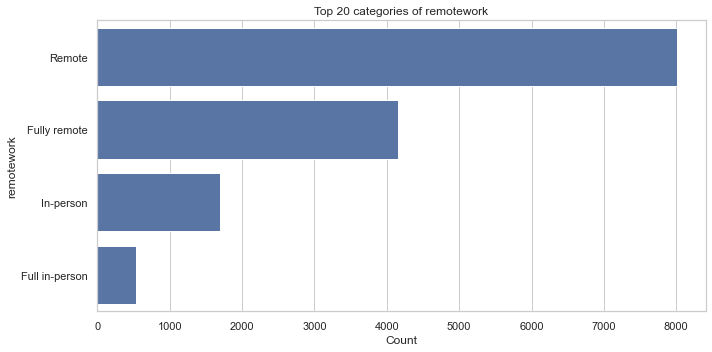

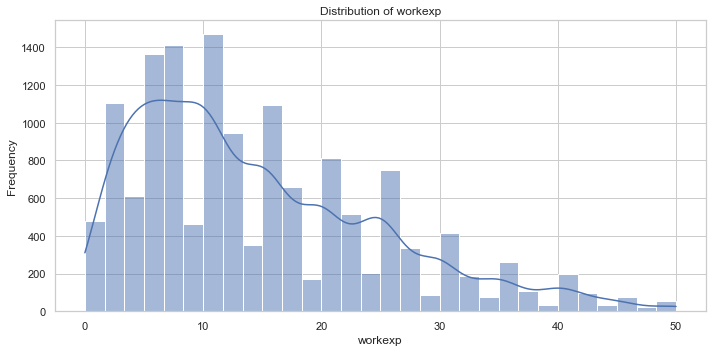

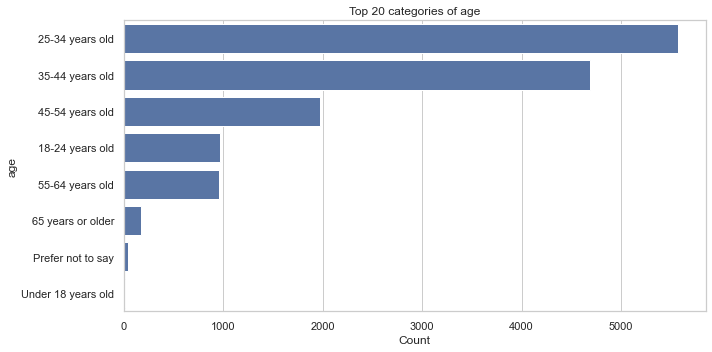

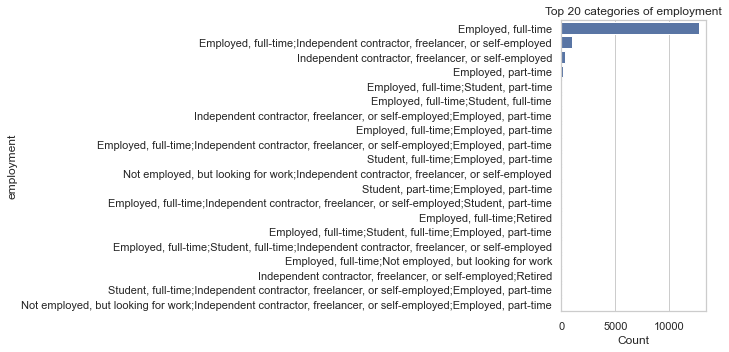

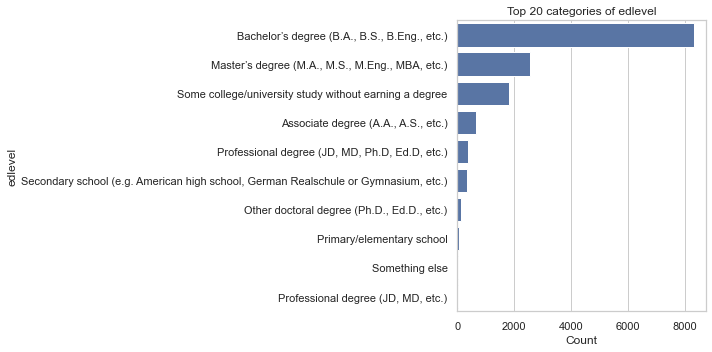

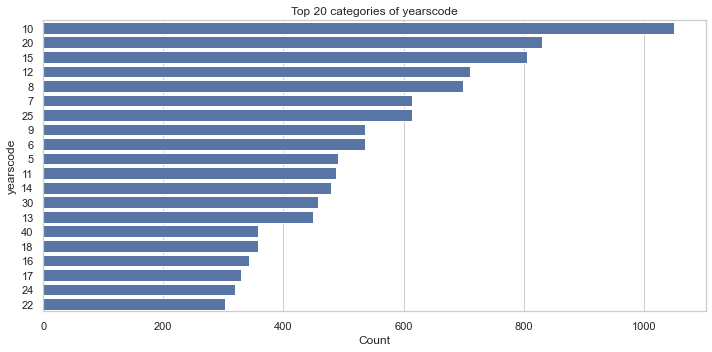

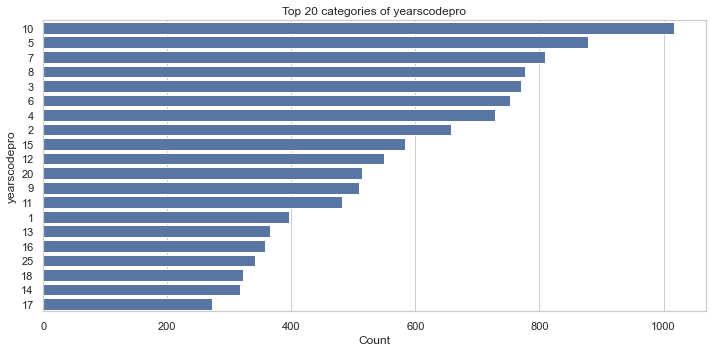

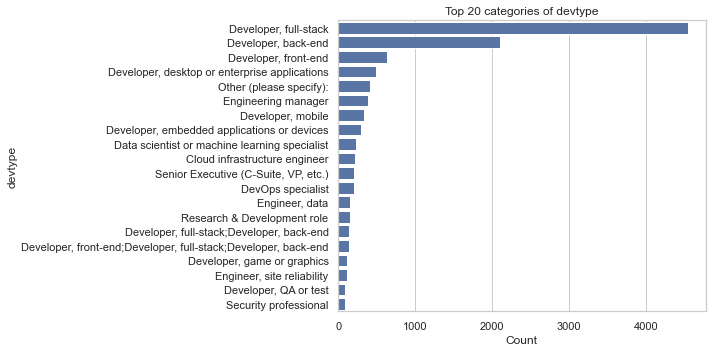

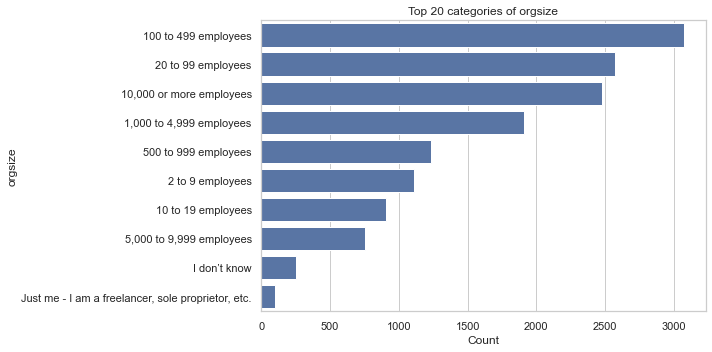

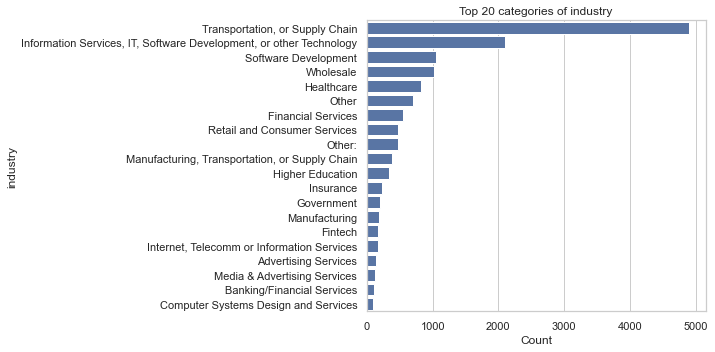

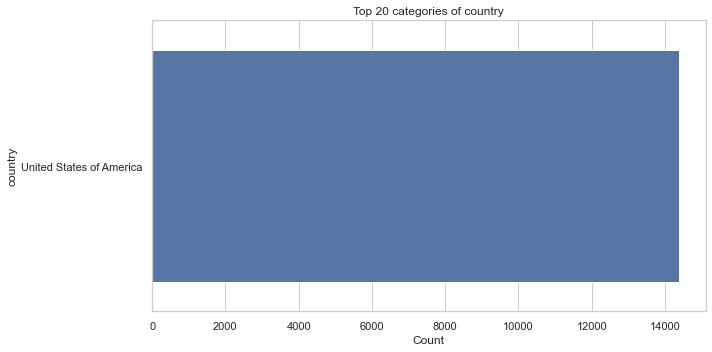

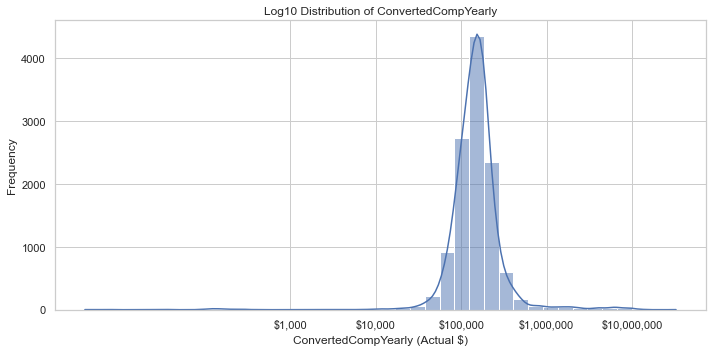

In [13]:
summary = analyze_features(df_completed)


In [14]:

def convert_experience_to_numeric(x):
    if pd.isna(x):
        return np.nan
    if isinstance(x, str):
        x = x.strip()
        if x.lower() == 'less than 1 year':
            return 0.5
        elif x.lower() == 'more than 50 years':
            return 51
        else:
            try:
                return float(x)
            except ValueError:
                return np.nan
    return x  # If already numeric


def unify_remotework(df, col="remotework"):

    mapping = {
        "remote": "Remote",
        "fully remote": "Remote",
        "in-person": "In-person",
        "full in-person": "In-person"
    }
    
    df = df.copy()
    df["remotework"] = df[col].str.lower().map(mapping)
    return df



In [15]:
df_completed= unify_remotework(df_completed)

# Matching and trimming

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegressionCV
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss



In [34]:
def preprocess_dataframe(df, confounders, convert_experience_to_numeric):
    """
    Preprocess dataset:
    1. Drop rows with NaN in confounders.
    2. Convert 'yearscode' and 'yearscodepro' to numeric using custom function.
    3. Add binary treatment column from 'remotework'.
    
    Parameters
    ----------
    df : pd.DataFrame
        Input dataset.
    confounders : list
        List of confounder column names.
    convert_experience_to_numeric : function
        Function to convert experience strings into numeric values.
        
    Returns
    -------
    df_clean : pd.DataFrame
        Cleaned DataFrame with added 'treatment' column.
    """
    before_rows = df.shape[0]
    # Create a binary indicator for senior developers
    # Drop missing values in confounders
    df_clean = df.dropna(subset=confounders).copy()
    after_rows = df_clean.shape[0]
    removed = before_rows - after_rows
    print(f" Removed {removed} rows due to NaN in confounders ({before_rows} → {after_rows})")

    # Convert experience columns if they exist
    if 'yearscode' in df_clean.columns:
        df_clean['yearscode'] = df_clean['yearscode'].apply(convert_experience_to_numeric)
    if 'yearscodepro' in df_clean.columns:
        df_clean['yearscodepro'] = df_clean['yearscodepro'].apply(convert_experience_to_numeric)
        
    df_clean['senior_dev'] = df_clean['yearscodepro'].apply(lambda x: 1 if x >= 5 else 0)  # Example threshold
    # Add treatment column
    if 'remotework' in df_clean.columns:
        df_clean['treatment'] = (
            df_clean['remotework']
            .astype(str)
            .str.lower()
            .str.strip()
            .apply(lambda x: 1 if 'remote' in x else 0)
        )
        print(" Added 'treatment' column (1=remote, 0=other)")
    else:
        raise KeyError("Column 'remotework' not found in DataFrame.")

    return df_clean


In [36]:
confounders = [
    'age', 'employment', 'edlevel', 'devtype','workexp',
    'orgsize', 'yearscode', 'yearscodepro','industry'
]

df_clean = preprocess_dataframe(df_us, confounders, convert_experience_to_numeric) #from the df_clean will create the subsets
df_clean = unify_remotework(df_clean)

df_completed = preprocess_dataframe(df_completed, confounders, convert_experience_to_numeric)
df_completed = unify_remotework(df_completed)
#drop na remote
df_completed = df_completed.dropna(subset=['remotework'])
df_clean = df_clean.dropna(subset=['remotework'])
print(df_clean.shape, df_completed.shape)

 Removed 30307 rows due to NaN in confounders (43285 → 12978)
 Added 'treatment' column (1=remote, 0=other)
 Removed 0 rows due to NaN in confounders (14389 → 14389)
 Added 'treatment' column (1=remote, 0=other)
(8588, 15) (14389, 15)


In [37]:
print(df_clean['remotework'].unique())
print(df_completed['remotework'].unique())

['Remote' 'In-person']
['Remote' 'In-person']


Null counts per feature:
Series([], dtype: int64)

DataFrame shape before filtering: (14389, 15)
DataFrame shape after filtering : (14389, 15)


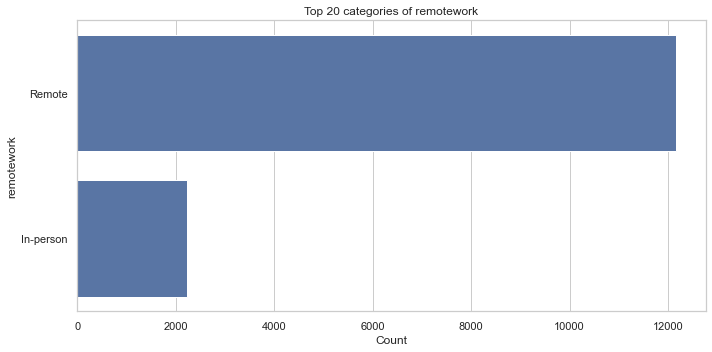

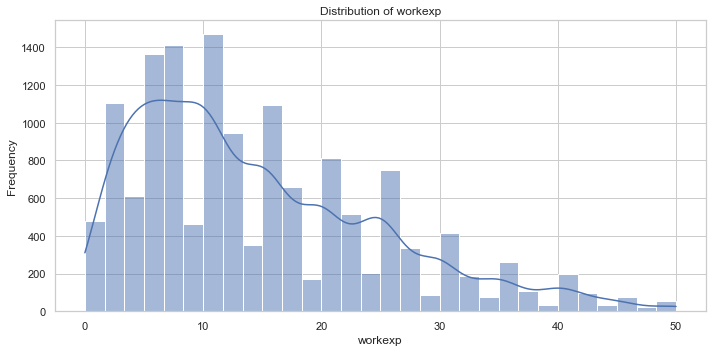

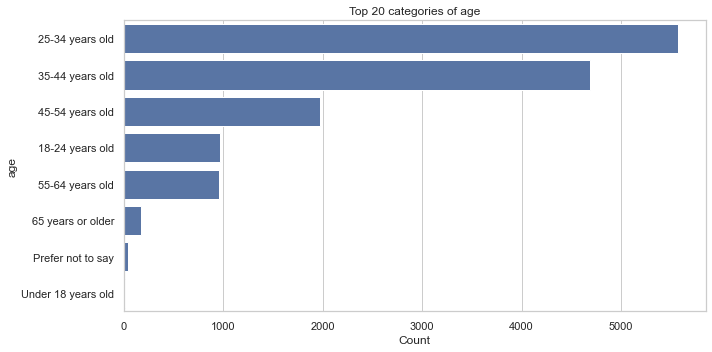

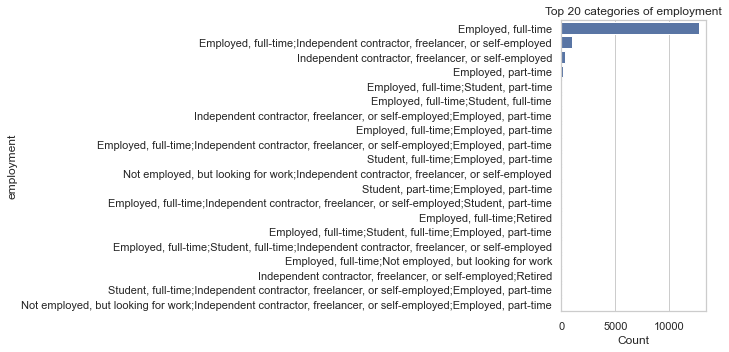

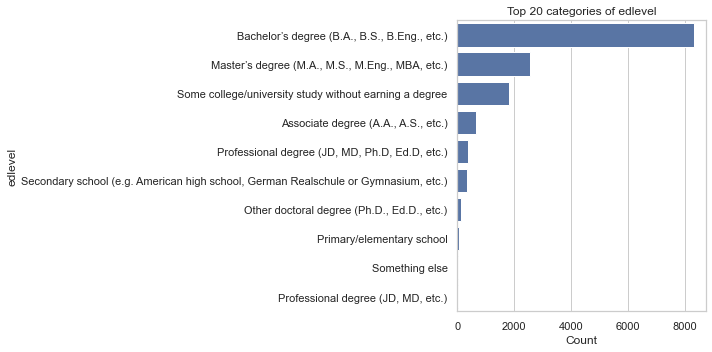

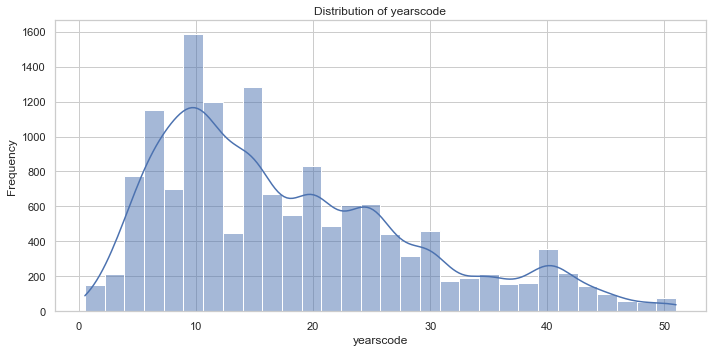

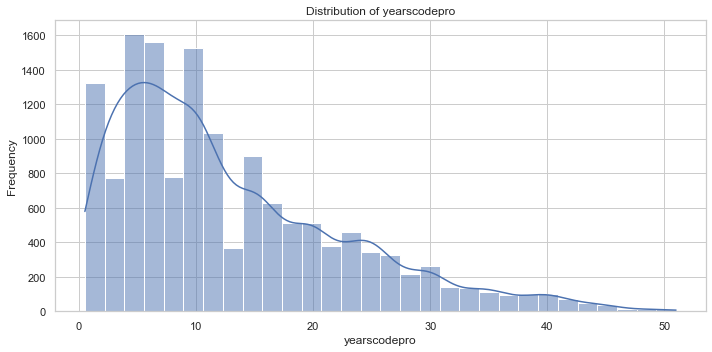

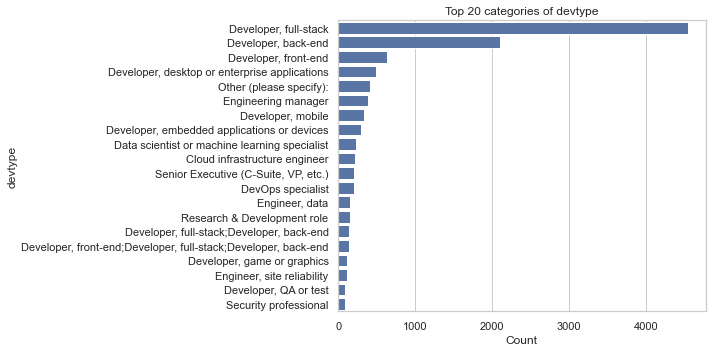

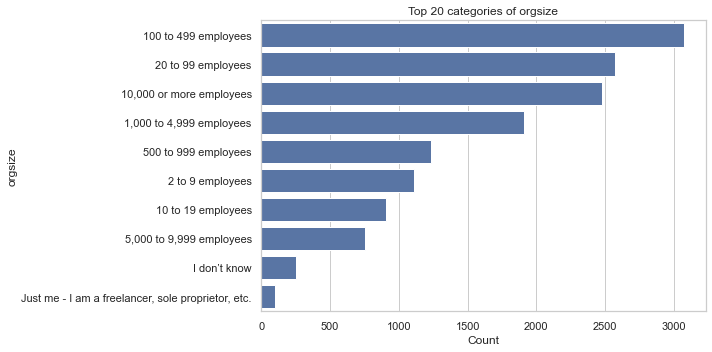

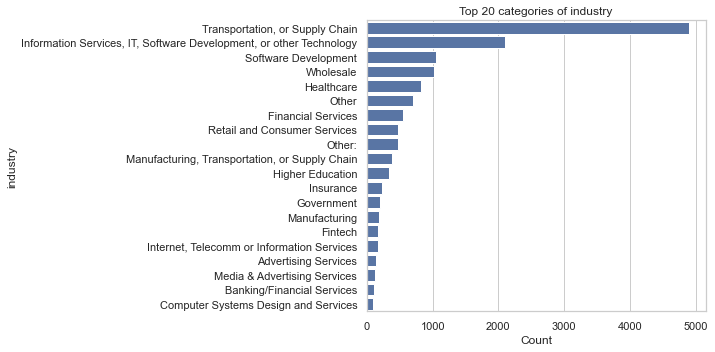

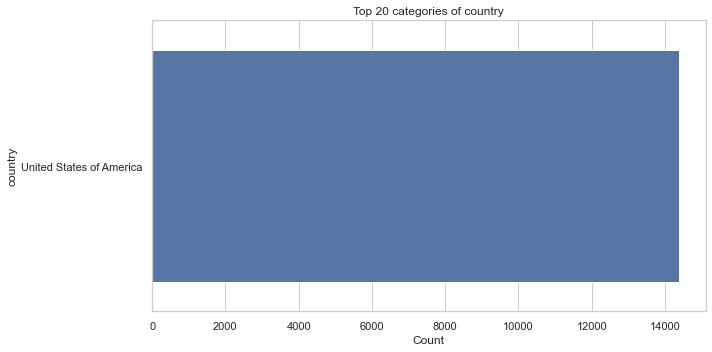

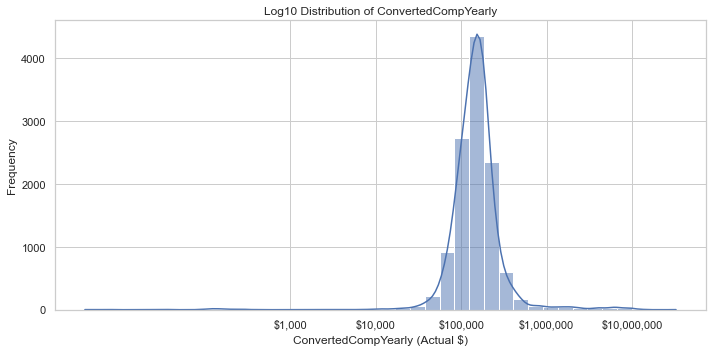

In [38]:
summary = analyze_features(df_completed)

Null counts per feature:
Series([], dtype: int64)

DataFrame shape before filtering: (8588, 15)
DataFrame shape after filtering : (8588, 15)


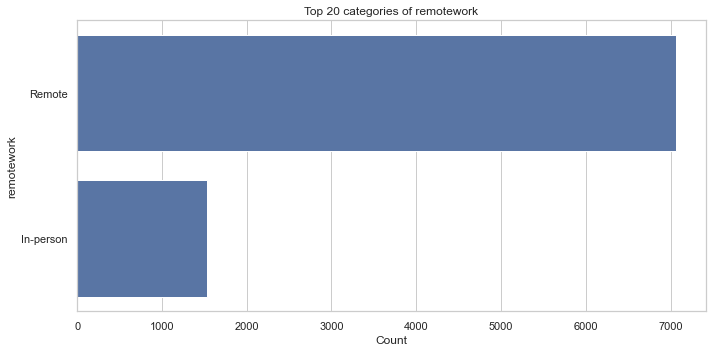

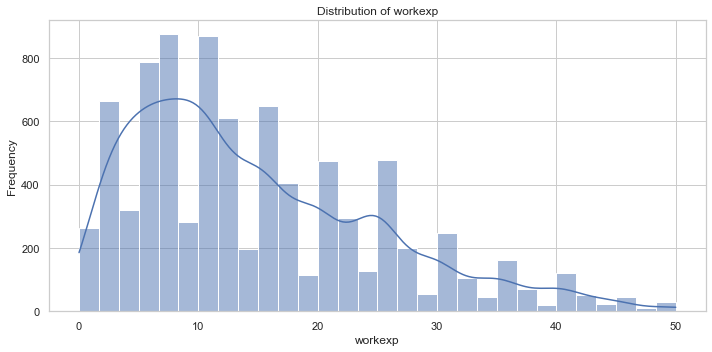

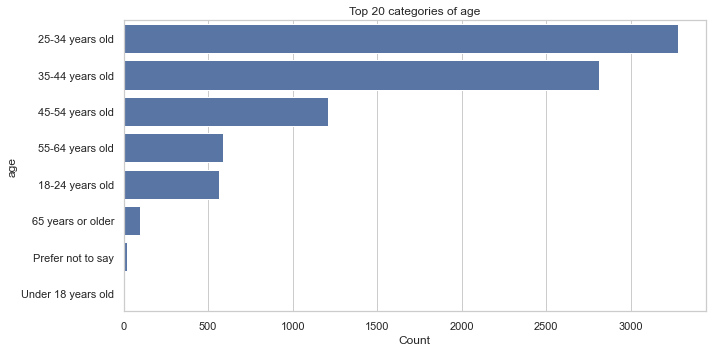

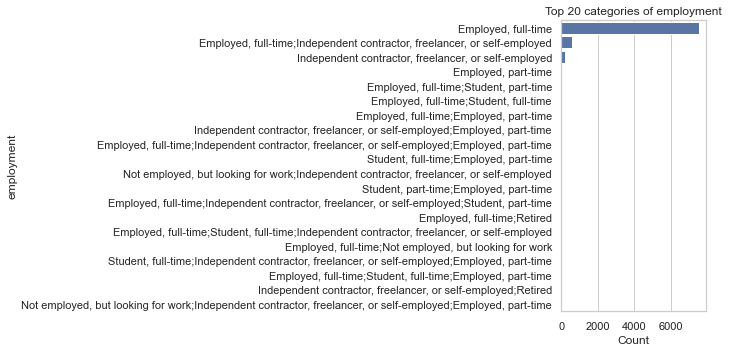

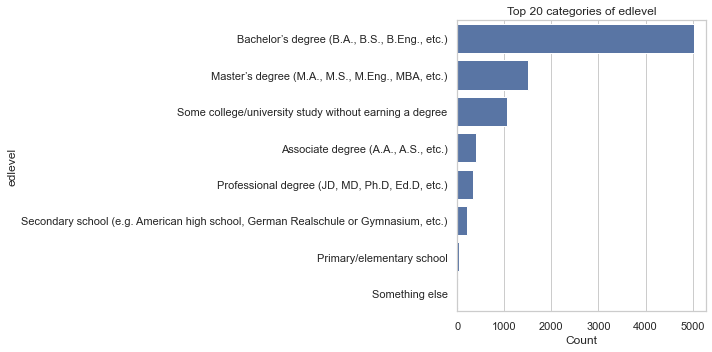

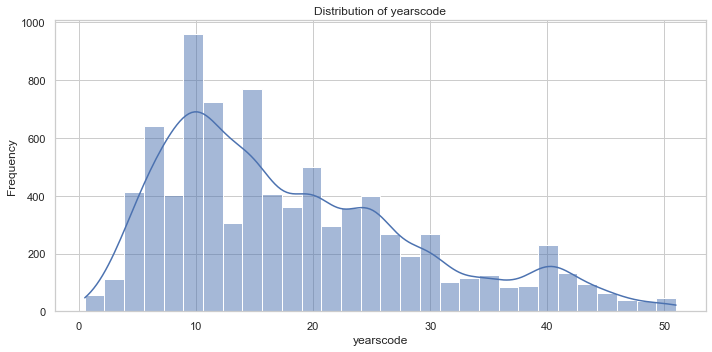

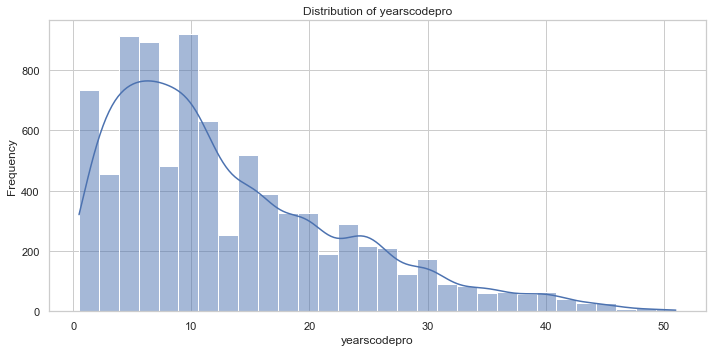

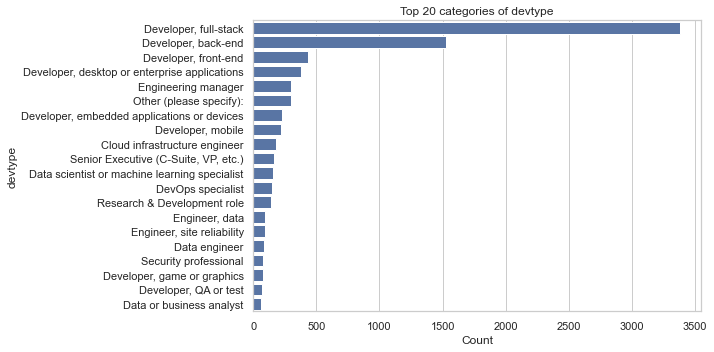

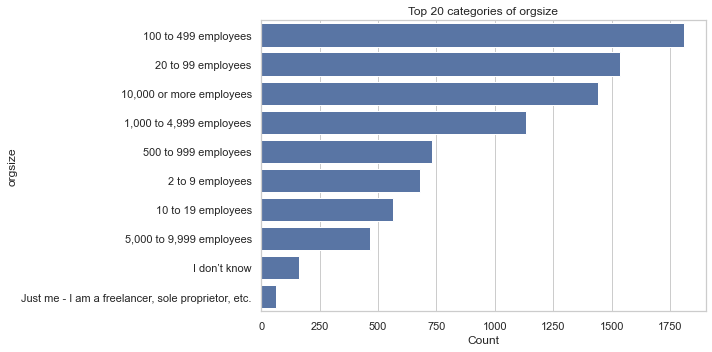

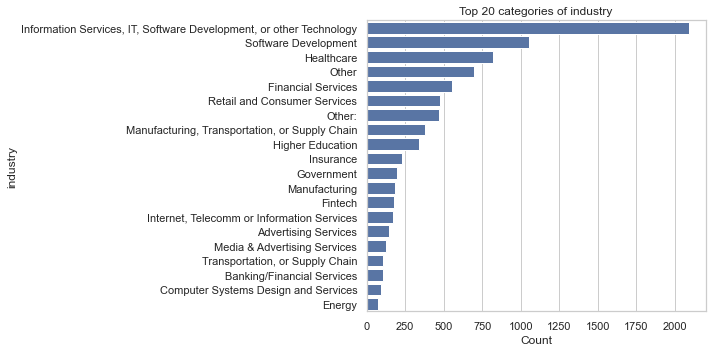

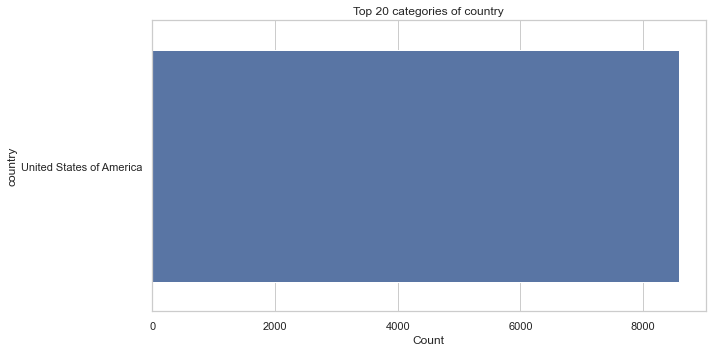

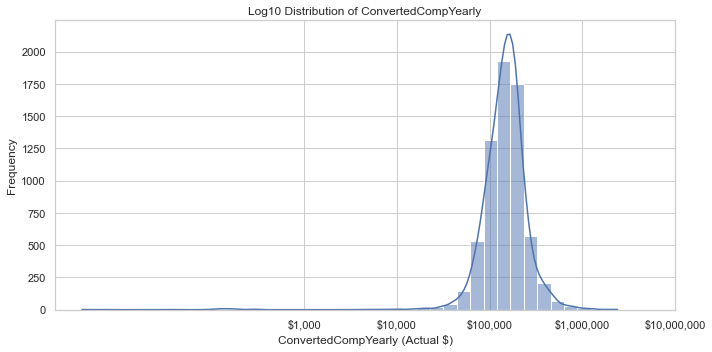

In [39]:
summary = analyze_features(df_clean)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegressionCV
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss


# Confounders country is removed because it US for all
confounders = [
    'age', 'employment', 'edlevel', 'devtype','workexp',
    'orgsize', 'yearscode', 'yearscodepro','industry'
]

# Drop missing
df_clean = df_clean.dropna(subset=confounders + ['treatment'])
df_completed = df_completed.dropna(subset=confounders + ['treatment'])



In [41]:
df_completed.head()

,remotework,workexp,convertedcompyearly,age,employment,edlevel,yearscode,yearscodepro,devtype,orgsize,industry,country,year,senior_dev,treatment
0,Remote,10.0,285000.0,25-34 years old,"Employed, full-time","Bachelor’s degree (B.A., B.S., B.Eng., etc.)",18.0,9.0,"Senior Executive (C-Suite, VP, etc.)",2 to 9 employees,"Information Services, IT, Software Development...",United States of America,2023,1,1
3,Remote,4.0,135000.0,35-44 years old,"Employed, full-time",Some college/university study without earning ...,4.0,3.0,"Developer, full-stack","1,000 to 4,999 employees","Information Services, IT, Software Development...",United States of America,2023,0,1
4,Remote,5.0,80000.0,25-34 years old,"Employed, full-time","Bachelor’s degree (B.A., B.S., B.Eng., etc.)",5.0,3.0,"Developer, full-stack",10 to 19 employees,Financial Services,United States of America,2023,0,1
5,Remote,3.0,NaN,25-34 years old,"Employed, full-time","Bachelor’s degree (B.A., B.S., B.Eng., etc.)",14.0,3.0,"Developer, desktop or enterprise applications",100 to 499 employees,Other,United States of America,2023,0,1
6,Remote,9.0,75000.0,25-34 years old,"Employed, full-time","Bachelor’s degree (B.A., B.S., B.Eng., etc.)",10.0,9.0,"Developer, full-stack",2 to 9 employees,Other,United States of America,2023,1,1


In [42]:
df_clean.head()

,remotework,workexp,convertedcompyearly,age,employment,edlevel,yearscode,yearscodepro,devtype,orgsize,industry,country,year,senior_dev,treatment
1,Remote,10.0,285000.0,25-34 years old,"Employed, full-time","Bachelor’s degree (B.A., B.S., B.Eng., etc.)",18.0,9.0,"Senior Executive (C-Suite, VP, etc.)",2 to 9 employees,"Information Services, IT, Software Development...",United States of America,2023,1,1
6,Remote,4.0,135000.0,35-44 years old,"Employed, full-time",Some college/university study without earning ...,4.0,3.0,"Developer, full-stack","1,000 to 4,999 employees","Information Services, IT, Software Development...",United States of America,2023,0,1
7,Remote,5.0,80000.0,25-34 years old,"Employed, full-time","Bachelor’s degree (B.A., B.S., B.Eng., etc.)",5.0,3.0,"Developer, full-stack",10 to 19 employees,Financial Services,United States of America,2023,0,1
10,Remote,3.0,NaN,25-34 years old,"Employed, full-time","Bachelor’s degree (B.A., B.S., B.Eng., etc.)",14.0,3.0,"Developer, desktop or enterprise applications",100 to 499 employees,Other,United States of America,2023,0,1
12,Remote,9.0,75000.0,25-34 years old,"Employed, full-time","Bachelor’s degree (B.A., B.S., B.Eng., etc.)",10.0,9.0,"Developer, full-stack",2 to 9 employees,Other,United States of America,2023,1,1


# Roubstness : Repeat the  pipeline for each subset

In [43]:
df_completed  #1
df_senior = df_completed[df_completed['senior_dev'] == 1] # 2
df_junior = df_completed[df_completed['senior_dev'] == 0] # 3

df_23_24 = df_completed[df_completed['year'].isin([2023, 2024])] #4

# Repeat the  pipeline for each subset





In [44]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
import pandas as pd

def propensity_model_selection(
    df_subset, features, treatment_col="treatment", random_seed=42, plot=True
):
    """
    Fit and compare propensity score models (Logistic Regression, XGBoost)
    on a subset of the data using Brier score and calibration curves.
    
    Parameters
    ----------
    df_subset : pd.DataFrame
        The subset dataset to analyze.
    features : list
        List of confounder features to use for propensity score estimation.
    treatment_col : str
        Column name for the treatment indicator (binary).
    random_seed : int
        Random seed for reproducibility.
    plot : bool
        Whether to plot calibration curves.
    
    Returns
    -------
    best_model : sklearn Pipeline
        The fitted pipeline (preprocessor + best model).
    brier_scores : dict
        Brier scores for each model.
    X_train, X_val, T_train, T_val, y : split data 
    """

    X = df_subset[features]
    T = df_subset[treatment_col]
    y = df_subset.get("convertedcompyearly")  # outcome, optional use later
    
    # Train-validation split
    X_train, X_val, T_train, T_val, y_train, y_val = train_test_split(X, T, y, test_size=0.3, random_state=random_seed)

    # Detect categorical features
    categorical = [c for c in features if df_subset[c].dtype == "object"]

    # Preprocessor
    preprocessor = ColumnTransformer(
        transformers=[("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), categorical)],
        remainder="passthrough"
    )

    # Candidate models
    models = {
        "Logistic Regression": LogisticRegressionCV(cv=5, solver="liblinear", random_state=random_seed),
        "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric="logloss", random_state=random_seed)
    }

    brier_scores = {}
    calibration_data = {}

    # Train and evaluate each model
    for name, clf in models.items():
        pipe = Pipeline([
            ("preprocess", preprocessor),
            ("model", clf)
        ])
        pipe.fit(X_train, T_train)
        probs = pipe.predict_proba(X_val)[:, 1]

        # Brier score
        brier = brier_score_loss(T_val, probs)
        brier_scores[name] = brier

        # Calibration curve
        frac_pos, mean_pred = calibration_curve(T_val, probs, n_bins=10)
        calibration_data[name] = (mean_pred, frac_pos)

    # Print results
    print("\n Brier Scores:")
    for name, score in brier_scores.items():
        print(f"{name}: {score:.4f}")

    # Choose best model
    best_model_name = min(brier_scores, key=brier_scores.get)
    print(f"\nBest Calibrated Model: {best_model_name}")

    # Refit best model on the whole training set
    best_model = Pipeline([
        ("preprocess", preprocessor),
        ("model", models[best_model_name])
    ])
    best_model.fit(X_train, T_train)

    # Plot calibration curves
    if plot:
        plt.figure(figsize=(10, 6))
        for name, (mean_pred, frac_pos) in calibration_data.items():
            plt.plot(mean_pred, frac_pos, marker="o", label=name)
        plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect Calibration")
        plt.xlabel("Mean Predicted Probability")
        plt.ylabel("Fraction of Positives")
        plt.title("Calibration Curves: Propensity for Treatment")
        plt.grid(True)
        plt.legend()
        plt.tight_layout()
        plt.show()

    return best_model, brier_scores, X, y, y_train, y_val, X_train, X_val, T, T_train, T_val, preprocessor


In [45]:
def compute_overlap_and_trim(
    best_model,
    X,
    T,
    y=None, 
    bins: int = 20,
    plot: bool = True,
    trim: bool = True,
    save: bool = True,
    save_path: str = "trimmed_dataset.csv",
    include_index: bool = False,
    feature_names: list | None = None,
):
    """
    Compute common support overlap for propensity scores, optionally trim,
    and save trimmed dataset (optionally including y).

    Parameters
    ----------
    best_model : sklearn Pipeline
        Fitted propensity model pipeline with predict_proba.
    X : pd.DataFrame or np.ndarray
        Features to compute propensity scores on.
    T : array-like
        Treatment indicator, values 0 or 1.
    y : array-like or pd.Series or None
        Outcome variable to optionally trim and save with data.
    ...
    """

    probs = best_model.predict_proba(X)[:, 1]
    probs = np.asarray(probs)
    T = np.asarray(T)

    # Compute bounds
    p0 = probs[T == 0]
    p1 = probs[T == 1]
    min_overlap = max(p0.min(), p1.min())
    max_overlap = min(p0.max(), p1.max())
    mask = (probs >= min_overlap) & (probs <= max_overlap)

    if plot:
        plt.figure(figsize=(10, 6))
        plt.hist(p0, bins=bins, alpha=0.6, label="Treatment = 0", color="blue")
        plt.hist(p1, bins=bins, alpha=0.6, label="Treatment = 1", color="red")
        plt.axvline(x=min_overlap, color="black", linestyle="--", label=f"Lower Trim = {min_overlap:.2f}")
        plt.axvline(x=max_overlap, color="black", linestyle="--", label=f"Upper Trim = {max_overlap:.2f}")
        plt.xlabel("Predicted Probability (Propensity Score)")
        plt.ylabel("Frequency")
        plt.title("Propensity Scores with Common Support Trimming")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()

    result = {
        "propensity_scores": probs,
        "min_overlap": float(min_overlap),
        "max_overlap": float(max_overlap),
        "mask_in_overlap": mask
    }

    if trim:
        if hasattr(X, "iloc"): 
            X_trim = X.loc[mask].copy()
            X_trim["treatment"] = T[mask]
            X_trim["propensity_score"] = probs[mask]
            if y is not None:
                y_trim = pd.Series(y).loc[mask].copy()
                X_trim["convertedcompyearly"] = y_trim
                result["y_trim"] = y_trim
        else:
            X_arr = X[mask]
            if feature_names is None:
                feature_names = [f"x{i}" for i in range(X_arr.shape[1])]
            X_trim = pd.DataFrame(X_arr, columns=feature_names)
            X_trim["treatment"] = T[mask]
            X_trim["propensity_score"] = probs[mask]
            if y is not None:
                y_trim = pd.Series(y)[mask].reset_index(drop=True)
                X_trim["convertedcompyearly"] = y_trim
                result["y_trim"] = y_trim

        T_trim = T[mask]
        result["X_trim"] = X_trim
        result["T_trim"] = T_trim

        if save:
            X_trim.to_csv(save_path, index=include_index)
            result["saved_path"] = save_path

    return result


# here switch Data freme for subset

c:\Users\Yuval Margolin\PycharmProjects\pythonProject\venv\lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning: Found unknown categories in columns [1, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
c:\Users\Yuval Margolin\PycharmProjects\pythonProject\venv\lib\site-packages\xgboost\training.py:183: UserWarning: [18:06:48] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\Yuval Margolin\PycharmProjects\pythonProject\venv\lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning: Found unknown categories in columns [1, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(



 Brier Scores:
Logistic Regression: 0.1059
XGBoost: 0.1105

Best Calibrated Model: Logistic Regression


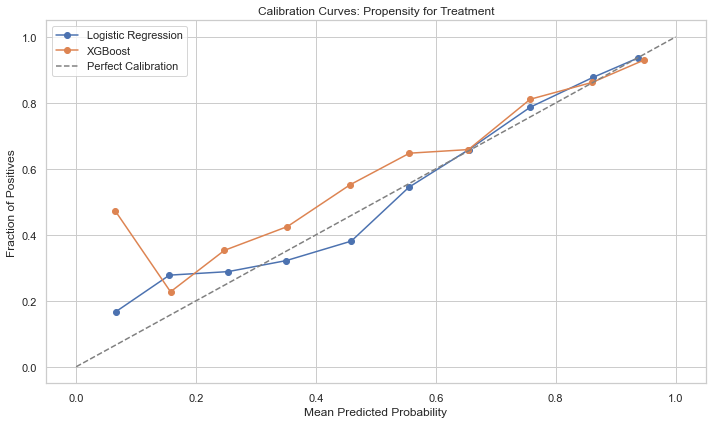

c:\Users\Yuval Margolin\PycharmProjects\pythonProject\venv\lib\site-packages\sklearn\preprocessing\_encoders.py:241: UserWarning: Found unknown categories in columns [1, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


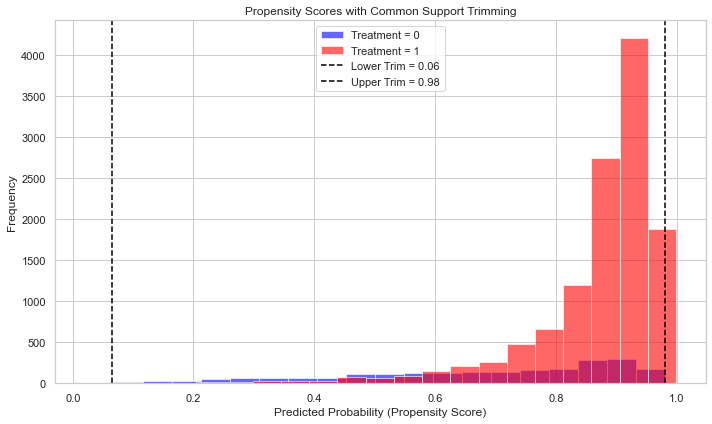

Overlap range: 0.06464027869872278 to 0.98095989775678
Kept samples: 14173 / 14389
Percentage dropped: 1.501146709291823 %


In [46]:
features = ['age','employment','edlevel','devtype','orgsize','industry',
            'workexp','yearscode','yearscodepro']

best_model, brier_scores, X, y, y_train, y_val, X_train, X_val, T, T_train, T_val,preprocessor = propensity_model_selection(
    df_completed, features, treatment_col="treatment"
)  #switch subset for robustness currently the difault is df_completed

res = compute_overlap_and_trim(
    best_model,
    X=X,
    T=T,
    y=y,
    save_path="df_completed_trimmed_dataset_with_y.csv"
)


print("Overlap range:", res["min_overlap"], "to", res["max_overlap"])
print("Kept samples:", res["mask_in_overlap"].sum(), "/", len(res["mask_in_overlap"]))
#precentage droped
print("Percentage dropped:", (1 - res["mask_in_overlap"].mean()) * 100, "%")


In [47]:

print("Saved to:", res.get("saved_path"))

Saved to: df_completed_trimmed_dataset_with_y.csv


# load trimmed data

In [48]:

df_subset =pd.read_csv("df_completed_trimmed_dataset_with_y.csv")
df_subset.columns

Index(['age', 'employment', 'edlevel', 'devtype', 'orgsize', 'industry',
       'workexp', 'yearscode', 'yearscodepro', 'treatment', 'propensity_score',
       'convertedcompyearly'],
      dtype='object')

# prepearing

In [49]:
random_seed=42
mask = y_train.notna()



X = df_subset[features]
T = df_subset["treatment"]
y = df_subset["convertedcompyearly"]

print("Initial shapes:")
print("X shape:", X.shape)
print("T shape:", T.shape)
print("y shape:", y.shape)


X_train, X_val, T_train, T_val, y_train, y_val = train_test_split(
    X, T, y, test_size=0.3, random_state=42
)
print("Train shapes:")
print("X_train shape:", X_train.shape)
print("T_train shape:", T_train.shape)
print("y_train shape:", y_train.shape)
print("X_val shape:", X_val.shape)
print("T_val shape:", T_val.shape)
print("y_val shape:", y_val.shape)


mask_train = y_train.notna()
X_train_overlap = X_train.loc[mask_train].copy()
y_train_overlap = y_train.loc[mask_train].copy()
T_train_overlap = T_train.loc[mask_train].copy()

mask_val = y_val.notna()
X_val_overlap = X_val.loc[mask_val].copy()
y_val_overlap = y_val.loc[mask_val].copy()
T_val_overlap = T_val.loc[mask_val].copy()


print("X_train_overlap shape:", X_train_overlap.shape)
print("y_train_overlap shape:", y_train_overlap.shape)
print("T_train_overlap shape:", T_train_overlap.shape)
print("X_val_overlap shape:", X_val_overlap.shape)
print("y_val_overlap shape:", y_val_overlap.shape)
print("T_val_overlap shape:", T_val_overlap.shape)

X_train_with_t = X_train_overlap.copy()
X_train_with_t['treatment'] = T_train_overlap.copy()
X_val_with_t = X_val_overlap.copy()
X_val_with_t['treatment'] = T_val_overlap.copy()


Initial shapes:
X shape: (14173, 9)
T shape: (14173,)
y shape: (14173,)
Train shapes:
X_train shape: (9921, 9)
T_train shape: (9921,)
y_train shape: (9921,)
X_val shape: (4252, 9)
T_val shape: (4252,)
y_val shape: (4252,)
X_train_overlap shape: (8150, 9)
y_train_overlap shape: (8150,)
T_train_overlap shape: (8150,)
X_val_overlap shape: (3433, 9)
y_val_overlap shape: (3433,)
T_val_overlap shape: (3433,)


# T-learner 

In [50]:
import numpy as np
import pandas as pd
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.base import clone


# RMSE metric
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


# Preprocessing

categorical_cols = ['age', 'employment', 'edlevel', 'devtype', 'orgsize', 'industry']
numerical_cols = [col for col in X_train_with_t.columns if col not in categorical_cols + ['treatment']]

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numerical_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
])

# Candidate models wrapped in pipeline
models = [
    Pipeline([('preprocessor', preprocessor),
              ('regressor', LinearRegression())]),

    Pipeline([('preprocessor', preprocessor),
              ('regressor', GradientBoostingRegressor(random_state=42))]),

    Pipeline([('preprocessor', preprocessor),
              ('regressor', RandomForestRegressor(random_state=42))])
]


# Model selection
def t_learner_model_selection(models, metric, X_train, y_train, X_val, y_val):
    best_score = float('inf')
    best_model = None

    for i, base_model in enumerate(models):
        model = clone(base_model)
        model.fit(X_train, y_train.values.ravel())
        y_pred = model.predict(X_val)
        score = metric(y_val, y_pred)

        model_name = base_model.named_steps['regressor'].__class__.__name__
        print(f"Model {i} ({model_name}): Validation {metric.__name__} = {score:.4f}")

        if score < best_score:
            best_score = score
            best_model = model

    print(f"\n Selected Best Model: {best_model.named_steps['regressor'].__class__.__name__} "
          f"(Validation {metric.__name__} = {best_score:.4f})\n")
    return best_model


# Train T-learners
mask1 = X_train_with_t['treatment'] == 1
X_train_1 = X_train_with_t.loc[mask1].drop(columns='treatment')
y_train_1 = y_train_overlap.loc[mask1]

X_val_1 = X_val_with_t.loc[X_val_with_t['treatment'] == 1].drop(columns='treatment')
y_val_1 = y_val_overlap.loc[X_val_with_t['treatment'] == 1]

fitted_t_learner_1 = t_learner_model_selection(models, rmse,
                                               X_train_1, y_train_1, X_val_1, y_val_1)

mask0 = X_train_with_t['treatment'] == 0
X_train_0 = X_train_with_t.loc[mask0].drop(columns='treatment')
y_train_0 = y_train_overlap.loc[mask0]

X_val_0 = X_val_with_t.loc[X_val_with_t['treatment'] == 0].drop(columns='treatment')
y_val_0 = y_val_overlap.loc[X_val_with_t['treatment'] == 0]

fitted_t_learner_0 = t_learner_model_selection(models, rmse,
                                               X_train_0, y_train_0, X_val_0, y_val_0)

# ATE estimation
def calculate_t_learner_ate(model_treated, model_control, X):
    y1_pred = model_treated.predict(X)
    y0_pred = model_control.predict(X)
    ate = np.mean(y1_pred - y0_pred)
    print(f"\n Estimated ATE (T-Learner): {ate:.4f}")
    return ate

X_val_for_ate = X_val_with_t.drop(columns='treatment', errors='ignore')
ate_point = calculate_t_learner_ate(fitted_t_learner_1, fitted_t_learner_0, X_val_for_ate)

# Bootstrap CI
def t_learner_confidence_intervals(model1, model0, X_val, n_bootstrap=2000, alpha=0.05, seed=42):
    np.random.seed(seed)
    n = len(X_val)

    y1_pred = model1.predict(X_val)
    y0_pred = model0.predict(X_val)
    ate_point = np.mean(y1_pred - y0_pred)

    ates = []
    for _ in range(n_bootstrap):
        idx = np.random.choice(n, n, replace=True)
        ates.append(np.mean(y1_pred[idx] - y0_pred[idx]))

    lower = np.percentile(ates, 100 * alpha / 2)
    upper = np.percentile(ates, 100 * (1 - alpha / 2))

    print(f"95% CI: [{lower:.4f}, {upper:.4f}]")
    return ate_point, lower, upper

t_ci = t_learner_confidence_intervals(fitted_t_learner_1, fitted_t_learner_0, X_val_for_ate)
print("\nFinal T-Learner Results:", t_ci)


Model 0 (LinearRegression): Validation rmse = 600389.3495
Model 1 (GradientBoostingRegressor): Validation rmse = 575906.9387
Model 2 (RandomForestRegressor): Validation rmse = 670719.2005

 Selected Best Model: GradientBoostingRegressor (Validation rmse = 575906.9387)

Model 0 (LinearRegression): Validation rmse = 366448.5242
Model 1 (GradientBoostingRegressor): Validation rmse = 354350.4114
Model 2 (RandomForestRegressor): Validation rmse = 339043.9237

 Selected Best Model: RandomForestRegressor (Validation rmse = 339043.9237)


 Estimated ATE (T-Learner): 63354.8101
95% CI: [58047.2484, 69167.6339]

Final T-Learner Results: (63354.81005169416, 58047.248408380874, 69167.63386397682)


# S-learner

In [60]:
import numpy as np
import pandas as pd
import warnings
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error
from sklearn.base import clone

warnings.filterwarnings("ignore", category=UserWarning, module='sklearn.preprocessing')

# --- Metric ---
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

# --- Preprocessing ---
categorical_cols = ['age', 'employment', 'edlevel', 'devtype', 'orgsize', 'industry']
numerical_cols = [col for col in X_train_with_t.columns if col not in categorical_cols + ['treatment']]
numerical_cols += ['treatment']  # include treatment as numerical feature

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numerical_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
])

# --- S-learner model selection ---
def s_learner_model_selection(models, metric, X_train, y_train, X_val, y_val):
    # drop rows with missing outcomes and features (train)
    mask_train = y_train.notna()
    X_train = X_train.loc[mask_train].copy()
    y_train = y_train.loc[mask_train].copy()
    mask_train_features = X_train.notna().all(axis=1)
    X_train = X_train.loc[mask_train_features]
    y_train = y_train.loc[mask_train_features]

    # drop rows with missing outcomes and features (val)
    mask_val = y_val.notna()
    X_val = X_val.loc[mask_val].copy()
    y_val = y_val.loc[mask_val].copy()
    mask_val_features = X_val.notna().all(axis=1)
    X_val = X_val.loc[mask_val_features]
    y_val = y_val.loc[mask_val_features]

    best_score = float('inf')
    best_model = None
    best_model_name = ""

    for i, model in enumerate(models):
        model_name = model.named_steps['regressor'].__class__.__name__
        # make Lasso variants identifiable
        if model_name == 'Lasso':
            model_name = f"Lasso(alpha={model.named_steps['regressor'].alpha})"

        print(f"\nTraining Model {i+1}: {model_name}")
        fitted_model = model.fit(X_train, y_train)
        y_pred = fitted_model.predict(X_val)
        score = metric(y_val, y_pred)
        print(f"{model_name} Validation {metric.__name__}: {score:.2f}")

        if score < best_score:
            best_score = score
            best_model = fitted_model
            best_model_name = model_name

    print(f"\nSelected Best Model: {best_model_name} (Validation {metric.__name__}: {best_score:.2f})")
    return best_model, best_model_name

# --- Utilities for ATE ---
def prepare_data_for_s_learner_inference(X):
    treatment_col = 'treatment'
    if isinstance(X, pd.DataFrame):
        X1 = X.copy(); X1[treatment_col] = 1
        X0 = X.copy(); X0[treatment_col] = 0
    elif isinstance(X, np.ndarray):
        X1 = np.concatenate([X, np.ones((X.shape[0], 1))], axis=1)
        X0 = np.concatenate([X, np.zeros((X.shape[0], 1))], axis=1)
    else:
        raise TypeError("Input X must be a pandas DataFrame or numpy array.")
    return X1, X0

def calculate_s_learner_ate(s_learner_model, X):
    X1, X0 = prepare_data_for_s_learner_inference(X)
    y1_pred = s_learner_model.predict(X1)
    y0_pred = s_learner_model.predict(X0)
    ate = np.mean(y1_pred - y0_pred)
    print(f"\nEstimated ATE (S-Learner): {ate:.2f}")
    return ate

# --- Bootstrap CI ---
def s_learner_confidence_intervals(s_learner_model, X_train_overlap, y_train_overlap, X_val, n_bootstrap=2000, random_state=42, alpha=0.05):
    def _reset(df_or_arr):
        return df_or_arr.reset_index(drop=True) if hasattr(df_or_arr, "reset_index") else df_or_arr

    X_val_fixed = _reset(X_val)
    X1_val, X0_val = prepare_data_for_s_learner_inference(X_val_fixed)

    rng = np.random.default_rng(random_state)
    X_train_r = _reset(X_train_overlap)
    y_train_r = _reset(y_train_overlap.squeeze())

    n_train = len(X_train_r)
    ates = []

    for _ in range(n_bootstrap):
        idx = rng.choice(n_train, n_train, replace=True)
        X_boot = X_train_r.iloc[idx] if isinstance(X_train_r, pd.DataFrame) else X_train_r[idx]
        y_boot = y_train_r.iloc[idx] if isinstance(y_train_r, pd.Series) else y_train_r[idx]

        model_b = clone(s_learner_model)
        model_b.fit(X_boot, y_boot)

        y1_pred = model_b.predict(X1_val)
        y0_pred = model_b.predict(X0_val)
        ates.append(np.mean(y1_pred - y0_pred))

    lower = np.percentile(ates, 100 * (alpha / 2))
    upper = np.percentile(ates, 100 * (1 - alpha / 2))
    point = np.mean(ates)

    print(f"\nEstimated ATE (bootstrap): {point:.2f}")
    print(f"{int((1 - alpha) * 100)}% CI: [{lower:.2f}, {upper:.2f}]")
    return point, lower, upper

# 1) MODEL SELECTION
base_models = [
    Pipeline([('preprocessor', preprocessor), ('regressor', LinearRegression())]),
    Pipeline([('preprocessor', preprocessor), ('regressor', GradientBoostingRegressor(random_state=42))]),
    Pipeline([('preprocessor', preprocessor), ('regressor', XGBRegressor(random_state=42, verbosity=0))]),
     Pipeline([('preprocessor', preprocessor), ('regressor', RandomForestRegressor(
        n_estimators=500, max_depth=None, random_state=42, n_jobs=-1))])
        
        
]

lasso_alphas = [0.05, 0.1, 0.2]
lasso_models = [
    Pipeline([('preprocessor', preprocessor), ('regressor', Lasso(alpha=a))]) for a in lasso_alphas
]
from sklearn.linear_model import Ridge

# Ridge models with different regularization strengths
ridge_alphas = [0.1, 1.0, 10.0]
ridge_models = [
    Pipeline([('preprocessor', preprocessor), ('regressor', Ridge(alpha=a, random_state=42))]) 
    for a in ridge_alphas
]

# Add Ridge into the pool
models = base_models + lasso_models + ridge_models



fitted_s_learner, best_model_name = s_learner_model_selection(
    models=models,
    metric=rmse,
    X_train=X_train_with_t,
    y_train=y_train_overlap,
    X_val=X_val_with_t,
    y_val=y_val_overlap
)

# 2) ATE WITH THE SELECTED MODEL
X_val_no_treatment = X_val_with_t.drop(columns='treatment', errors='ignore')
ate_estimate = calculate_s_learner_ate(fitted_s_learner, X_val_no_treatment)





Training Model 1: LinearRegression
LinearRegression Validation rmse: 568842.29

Training Model 2: GradientBoostingRegressor
GradientBoostingRegressor Validation rmse: 542077.30

Training Model 3: XGBRegressor
XGBRegressor Validation rmse: 607174.98

Training Model 4: RandomForestRegressor
RandomForestRegressor Validation rmse: 631674.94

Training Model 5: Lasso(alpha=0.05)


c:\Users\Yuval Margolin\PycharmProjects\pythonProject\venv\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:639: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 1194579915162802.2, tolerance: 363337418137.09106
  model = cd_fast.sparse_enet_coordinate_descent(


Lasso(alpha=0.05) Validation rmse: 569058.16

Training Model 6: Lasso(alpha=0.1)


c:\Users\Yuval Margolin\PycharmProjects\pythonProject\venv\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:639: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 1183807956799836.8, tolerance: 363337418137.09106
  model = cd_fast.sparse_enet_coordinate_descent(


Lasso(alpha=0.1) Validation rmse: 569904.49

Training Model 7: Lasso(alpha=0.2)


c:\Users\Yuval Margolin\PycharmProjects\pythonProject\venv\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:639: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 1030977450180257.0, tolerance: 363337418137.09106
  model = cd_fast.sparse_enet_coordinate_descent(


Lasso(alpha=0.2) Validation rmse: 570766.98

Training Model 8: Ridge
Ridge Validation rmse: 565104.82

Training Model 9: Ridge
Ridge Validation rmse: 548974.16

Training Model 10: Ridge
Ridge Validation rmse: 531834.23

Selected Best Model: Ridge (Validation rmse: 531834.23)

Estimated ATE (S-Learner): 36726.35


In [61]:
print("\nCalculating confidence intervals for S-Learner...")
ci_point, ci_lower, ci_upper = s_learner_confidence_intervals(
    fitted_s_learner,
    X_train_overlap=X_train_with_t,
    y_train_overlap=y_train_overlap,
    X_val=X_val_no_treatment
)

print("\nFinal S-Learner Results:", (ate_estimate, ci_lower, ci_upper))


Calculating confidence intervals for S-Learner...

Estimated ATE (bootstrap): 36431.25
95% CI: [10902.25, 61621.82]

Final S-Learner Results: (36726.353201723236, 10902.25432555965, 61621.82005494439)


# S-learner with IPW

In [54]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression, Ridge, Lasso
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from joblib import Parallel, delayed


# 1. Preprocessing 
categorical_cols = ['age', 'employment', 'edlevel', 'devtype', 'orgsize', 'industry']
numerical_cols = [c for c in X_train_with_t.columns if c not in categorical_cols + ['treatment']]

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numerical_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
])
preprocessor.fit(X_train_with_t.drop(columns="treatment"))


# 2. Fit weighted S-learner and helper
def fit_weighted_s_learner(base_model, X_train, T_train, y_train):
    # Estimate propensity scores
    ps_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("clf", LogisticRegression(max_iter=1000, solver="lbfgs"))
    ])
    ps_pipeline.fit(X_train, T_train)
    ps = ps_pipeline.predict_proba(X_train)[:, 1]
    ps = np.clip(ps, 0.01, 0.99)

    # IPW weights
    w = np.where(T_train == 1, 1 / ps, 1 / (1 - ps))

    # Prepare input for S-learner
    X_proc = preprocessor.transform(X_train)
    X_proc = np.hstack([X_proc, T_train.values.reshape(-1, 1)])

    model = clone(base_model)
    model.fit(X_proc, y_train, sample_weight=w)
    return model

def calculate_weighted_s_ate(model, X_val):
    X_proc = preprocessor.transform(X_val)
    X1 = np.hstack([X_proc, np.ones((X_proc.shape[0], 1))])
    X0 = np.hstack([X_proc, np.zeros((X_proc.shape[0], 1))])
    return np.mean(model.predict(X1) - model.predict(X0))


# 3. Model selection (cross-validated RMSE)
def select_best_model(X_train, T_train, y_train):
    from sklearn.metrics import make_scorer

    # Custom RMSE scorer (minimization goal)
    rmse = make_scorer(lambda y_true, y_pred: np.sqrt(np.mean((y_true - y_pred) ** 2)),
                       greater_is_better=False)

    # Estimate propensity scores
    ps_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("clf", LogisticRegression(max_iter=1000, solver="lbfgs"))
    ])
    ps_pipeline.fit(X_train, T_train)
    ps = ps_pipeline.predict_proba(X_train)[:, 1]
    ps = np.clip(ps, 0.01, 0.99)
    w = np.where(T_train == 1, 1 / ps, 1 / (1 - ps))

    # Prepare features
    X_proc = preprocessor.transform(X_train)
    X_proc = np.hstack([X_proc, T_train.values.reshape(-1, 1)])

    models = {
        "HistGBR": HistGradientBoostingRegressor(random_state=42),
        "RandomForest": RandomForestRegressor(random_state=42),
        "Ridge": Ridge(alpha=1.0),
        "Lasso": Lasso(alpha=0.1)
    }

    best_model = None
    best_score = float('inf')
    for name, model in models.items():
        scores = cross_val_score(
            model, X_proc, y_train, cv=3,
            scoring=rmse,
            fit_params={"sample_weight": w}
        )
        mean_rmse = -np.mean(scores)  # Negate because greater_is_better=False
        print(f"{name} - CV RMSE: {mean_rmse:.4f}")
        if mean_rmse < best_score:
            best_score = mean_rmse
            best_model = model

    print(f"\n Selected model: {best_model.__class__.__name__}")
    return best_model


# 4. Bootstrap ATE estimation
def weighted_s_learner_bootstrap(base_model, X_train, T_train, y_train, X_val,
                                 n_bootstrap=200, alpha=0.05, random_state=42):
    rng = np.random.default_rng(random_state)
    n = len(X_train)

    # Point estimate
    model_full = fit_weighted_s_learner(base_model, X_train, T_train, y_train)
    ate_point = calculate_weighted_s_ate(model_full, X_val)

    def one_bootstrap(i):
        rng_local = np.random.default_rng(random_state + i)
        idx = rng_local.choice(n, n, replace=True)
        X_b, T_b, y_b = X_train.iloc[idx], T_train.iloc[idx], y_train.iloc[idx]
        model_b = fit_weighted_s_learner(base_model, X_b, T_b, y_b)
        return calculate_weighted_s_ate(model_b, X_val)

    ate_bootstrap = Parallel(n_jobs=-1)(
        delayed(one_bootstrap)(i) for i in range(n_bootstrap)
    )

    lower = np.percentile(ate_bootstrap, 100 * alpha / 2)
    upper = np.percentile(ate_bootstrap, 100 * (1 - alpha / 2))

    print("\n Weighted S-Learner - IPW")
    print(f"Model used: {base_model.__class__.__name__}")
    print(f"ATE (point estimate): {ate_point:.4f}")
    print(f"{100 * (1 - alpha):.0f}% CI: [{lower:.4f}, {upper:.4f}]")

    return ate_point, lower, upper


# 5. Run model selection + bootstrap
X_train = X_train_with_t.drop(columns="treatment")
X_val_no_t = X_val_with_t.drop(columns="treatment", errors="ignore")

selected_model = select_best_model(X_train, T_train_overlap, y_train_overlap)




c:\Users\Yuval Margolin\PycharmProjects\pythonProject\venv\lib\site-packages\sklearn\model_selection\_validation.py:73: FutureWarning: `fit_params` is deprecated and will be removed in version 1.6. Pass parameters via `params` instead.
  warnings.warn(


HistGBR - CV RMSE: 681612.6662


c:\Users\Yuval Margolin\PycharmProjects\pythonProject\venv\lib\site-packages\sklearn\model_selection\_validation.py:73: FutureWarning: `fit_params` is deprecated and will be removed in version 1.6. Pass parameters via `params` instead.
  warnings.warn(


RandomForest - CV RMSE: 733396.4936


c:\Users\Yuval Margolin\PycharmProjects\pythonProject\venv\lib\site-packages\sklearn\model_selection\_validation.py:73: FutureWarning: `fit_params` is deprecated and will be removed in version 1.6. Pass parameters via `params` instead.
  warnings.warn(


Ridge - CV RMSE: 677652.2053


c:\Users\Yuval Margolin\PycharmProjects\pythonProject\venv\lib\site-packages\sklearn\model_selection\_validation.py:73: FutureWarning: `fit_params` is deprecated and will be removed in version 1.6. Pass parameters via `params` instead.
  warnings.warn(
c:\Users\Yuval Margolin\PycharmProjects\pythonProject\venv\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:678: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.002e+14, tolerance: 1.557e+11
  model = cd_fast.enet_coordinate_descent(
c:\Users\Yuval Margolin\PycharmProjects\pythonProject\venv\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:678: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.999e+14, tolerance: 1.555e+11
  model = cd_fast.

Lasso - CV RMSE: 702561.6120

 Selected model: Ridge


c:\Users\Yuval Margolin\PycharmProjects\pythonProject\venv\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:678: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.390e+14, tolerance: 1.863e+11
  model = cd_fast.enet_coordinate_descent(


In [55]:
weighted_s_results = weighted_s_learner_bootstrap(
    base_model=selected_model,
    X_train=X_train,
    T_train=T_train_overlap,
    y_train=y_train_overlap,
    X_val=X_val_no_t,
    n_bootstrap=1000,
    alpha=0.05
)


 Weighted S-Learner - IPW
Model used: Ridge
ATE (point estimate): 29100.5101
95% CI: [5483.4841, 51559.7891]


# Placebo

In [56]:
from sklearn.linear_model import Ridge
import scipy.stats as stats

def run_placebo_test(
    df,
    X_train_with_t,
    X_val_with_t,
    T_train_overlap,
    placebo_outcome_var,
    base_model=None,
    n_bootstrap=500,
    alpha=0.05
):
    """
    Run a placebo test using IPW-S-Learner with a specified placebo outcome.
    Returns ATE, CI, and an approximate p-value.
    """
    if base_model is None:
        base_model = Ridge(random_state=42)

    # Extract and preprocess the placebo outcome
    y_placebo_raw = df.loc[X_train_with_t.index, placebo_outcome_var]
    if y_placebo_raw.dtype.name == "category" or y_placebo_raw.dtype == object:
        y_placebo = y_placebo_raw.astype("category").cat.codes
    else:
        y_placebo = y_placebo_raw

    # Run bootstrap ATE estimation
    placebo_results = weighted_s_learner_bootstrap(
        base_model=base_model,
        X_train=X_train_with_t.drop(columns="treatment"),
        T_train=T_train_overlap,
        y_train=y_placebo,
        X_val=X_val_with_t.drop(columns="treatment", errors="ignore"),
        n_bootstrap=n_bootstrap,
        alpha=alpha
    )

    ate, lower_ci, upper_ci = placebo_results

    # Estimate standard error from CI bounds (approximation assuming normality)
    z_score = stats.norm.ppf(1 - alpha / 2)
    se = (upper_ci - lower_ci) / (2 * z_score)

    # Calculate two-sided p-value under normality assumption
    p_value = 2 * (1 - stats.norm.cdf(abs(ate / se)))

    print(f"\n Placebo Test Result (Outcome: '{placebo_outcome_var}')")
    print("ATE (should be ~0):", ate)
    print("95% CI:", (lower_ci, upper_ci))
    print("p-value:", p_value)

    return ate, lower_ci, upper_ci, p_value


In [57]:
run_placebo_test(df_subset, X_train_with_t, X_val_with_t, T_train_overlap, "edlevel")
run_placebo_test(df_subset, X_train_with_t, X_val_with_t, T_train_overlap, "age")
run_placebo_test(df_subset, X_train_with_t, X_val_with_t, T_train_overlap, "yearscode")
run_placebo_test(df_subset, X_train_with_t, X_val_with_t, T_train_overlap, "orgsize")
run_placebo_test(df_subset, X_train_with_t, X_val_with_t, T_train_overlap, "devtype") 



 Weighted S-Learner - IPW
Model used: Ridge
ATE (point estimate): 0.0004
95% CI: [0.0001, 0.0007]

 Placebo Test Result (Outcome: 'edlevel')
ATE (should be ~0): 0.0003593180194751619
95% CI: (0.00011673221228209058, 0.000693037522724256)
p-value: 0.014524687727759389

 Weighted S-Learner - IPW
Model used: Ridge
ATE (point estimate): -0.0000
95% CI: [-0.0004, 0.0006]

 Placebo Test Result (Outcome: 'age')
ATE (should be ~0): -4.180603783766022e-05
95% CI: (-0.00042794095555768796, 0.0005531001769798034)
p-value: 0.8673357314095238

 Weighted S-Learner - IPW
Model used: Ridge
ATE (point estimate): 0.0000
95% CI: [-0.0001, 0.0001]

 Placebo Test Result (Outcome: 'yearscode')
ATE (should be ~0): 4.794918021031546e-05
95% CI: (-6.781569698515666e-05, 0.00014527792979000128)
p-value: 0.3777545929218342

 Weighted S-Learner - IPW
Model used: Ridge
ATE (point estimate): -0.0001
95% CI: [-0.0004, 0.0007]

 Placebo Test Result (Outcome: 'orgsize')
ATE (should be ~0): -6.43711036197845e-05
95% C

(1.0216570720745728,
 -0.04703858154535843,
 1.3557768471025142,
 0.004305769062250109)